# 06 - TF-IDF with 3 seeds + combined comparison with XLM-R
Runs on your **laptop** (no GPU, about 2 to 5 minutes).

**Why:** In Week 5, XLM-R was averaged over 3 seeds, but TF-IDF was compared using a single run. Here TF-IDF is run on the **same 3 seeds and the same Roman Urdu subsets** (`random_state` = seed), including the shuffled-label control, so the comparison is fair.

**Needs:** `docs/xlmr_seeds_summary.csv` (from Week 5) and the 3 files in `data/raw`.

Run cells top to bottom (Shift + Enter).

In [1]:
import sys; sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

RAW = Path('../data/raw')
DOCS = Path('../docs')
NUM_TO_NAME = {0: 'positive', 1: 'neutral', 2: 'negative'}

## 1. Load data (identical cleaning and split as Weeks 2 to 5)

In [2]:
def load_multilingual(name):
    df = pd.read_csv(RAW / name)
    if pd.api.types.is_numeric_dtype(df['label']):
        df['label'] = df['label'].map(NUM_TO_NAME)
    df['text'] = df['text'].astype(str)
    return df[['text', 'label']].dropna().drop_duplicates(subset='text')

en = load_multilingual('english_train.csv')
it = load_multilingual('italian_train.csv')

ru = pd.read_csv(RAW / 'roman_urdu.csv', header=None, usecols=[0, 1],
                 names=['text', 'label'], on_bad_lines='skip').dropna(subset=['text'])
ru['label'] = ru['label'].str.strip().str.lower().replace({'neative': 'negative'})
ru['text'] = ru['text'].astype(str)
ru = ru[ru['text'].str.strip() != ''].drop_duplicates(subset='text')

ru_train, ru_test = train_test_split(ru, test_size=0.2, stratify=ru['label'], random_state=42)
foreign = pd.concat([en, it])
print('English:', len(en), ' Italian:', len(it), ' RU train:', len(ru_train), ' RU test:', len(ru_test))

English: 1839  Italian: 1839  RU train: 15700  RU test: 3926


## 2. Helpers

In [3]:
def train_and_test(train_df):
    model = make_pipeline(
        TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True),
        LinearSVC(C=1.0, class_weight='balanced'),
    )
    model.fit(train_df['text'], train_df['label'])
    pred = model.predict(ru_test['text'])
    return (round(accuracy_score(ru_test['label'], pred), 3),
            round(f1_score(ru_test['label'], pred, average='macro'), 3))

def shuffled_labels(df, seed):
    out = df.copy()
    out['label'] = np.random.default_rng(seed).permutation(out['label'].values)
    return out

## 3. Run all TF-IDF experiments (same seeds and subsets as XLM-R)

In [4]:
SEEDS = [42, 43, 44]
SIZES = [100, 500, 2000]
rows = []

def add(condition, ru_n, seed, train_df):
    acc, f1 = train_and_test(train_df)
    rows.append({'condition': condition, 'ru_n': ru_n, 'seed': seed, 'accuracy': acc, 'macro_f1': f1})
    print(rows[-1])

for seed in SEEDS:
    add('zero-shot EN+IT', 0, seed, foreign)                  # same result every seed (no randomness)
    add('RU only', len(ru_train), seed, ru_train)              # full data, same every seed
    for n in SIZES:
        sample = ru_train.sample(n=n, random_state=seed)       # same subset as in the XLM-R notebook
        add('RU only', n, seed, sample)
        add('EN+IT + RU', n, seed, pd.concat([foreign, sample]))
        add('EN+IT shuffled labels + RU', n, seed, pd.concat([shuffled_labels(foreign, seed), sample]))

tfidf_res = pd.DataFrame(rows)
tfidf_res.to_csv(DOCS / 'tfidf_seeds_results.csv', index=False)
print('runs:', len(tfidf_res))

{'condition': 'zero-shot EN+IT', 'ru_n': 0, 'seed': 42, 'accuracy': 0.375, 'macro_f1': 0.345}
{'condition': 'RU only', 'ru_n': 15700, 'seed': 42, 'accuracy': 0.66, 'macro_f1': 0.653}
{'condition': 'RU only', 'ru_n': 100, 'seed': 42, 'accuracy': 0.433, 'macro_f1': 0.421}
{'condition': 'EN+IT + RU', 'ru_n': 100, 'seed': 42, 'accuracy': 0.423, 'macro_f1': 0.414}
{'condition': 'EN+IT shuffled labels + RU', 'ru_n': 100, 'seed': 42, 'accuracy': 0.375, 'macro_f1': 0.36}
{'condition': 'RU only', 'ru_n': 500, 'seed': 42, 'accuracy': 0.536, 'macro_f1': 0.517}
{'condition': 'EN+IT + RU', 'ru_n': 500, 'seed': 42, 'accuracy': 0.506, 'macro_f1': 0.491}
{'condition': 'EN+IT shuffled labels + RU', 'ru_n': 500, 'seed': 42, 'accuracy': 0.478, 'macro_f1': 0.465}
{'condition': 'RU only', 'ru_n': 2000, 'seed': 42, 'accuracy': 0.586, 'macro_f1': 0.574}
{'condition': 'EN+IT + RU', 'ru_n': 2000, 'seed': 42, 'accuracy': 0.571, 'macro_f1': 0.561}
{'condition': 'EN+IT shuffled labels + RU', 'ru_n': 2000, 'seed':

## 4. TF-IDF summary (mean and std over 3 seeds)

In [5]:
def summarize(res):
    return (res.groupby(['condition', 'ru_n'])
               .agg(runs=('seed', 'count'), f1_mean=('macro_f1', 'mean'), f1_std=('macro_f1', 'std'),
                    f1_min=('macro_f1', 'min'), f1_max=('macro_f1', 'max'), acc_mean=('accuracy', 'mean'))
               .round(3).reset_index().sort_values(['ru_n', 'condition']))

tfidf_sum = summarize(tfidf_res)
tfidf_sum.to_csv(DOCS / 'tfidf_seeds_summary.csv', index=False)
tfidf_sum

,condition,ru_n,runs,f1_mean,f1_std,f1_min,f1_max,acc_mean
10,zero-shot EN+IT,0,3,0.345,0.000,0.345,0.345,0.375
0,EN+IT + RU,100,3,0.410,0.007,0.402,0.414,0.426
3,EN+IT shuffled labels + RU,100,3,0.371,0.017,0.360,0.390,0.387
6,RU only,100,3,0.442,0.019,0.421,0.456,0.462
1,EN+IT + RU,500,3,0.480,0.011,0.470,0.491,0.496
4,EN+IT shuffled labels + RU,500,3,0.460,0.006,0.454,0.465,0.475
7,RU only,500,3,0.505,0.017,0.486,0.517,0.526
2,EN+IT + RU,2000,3,0.559,0.005,0.554,0.563,0.569
5,EN+IT shuffled labels + RU,2000,3,0.551,0.002,0.550,0.553,0.562
8,RU only,2000,3,0.575,0.004,0.571,0.579,0.587


## 5. Combined table: TF-IDF vs XLM-R (mean +/- std)

In [6]:
xlmr_sum = pd.read_csv(DOCS / 'xlmr_seeds_summary.csv')

a = tfidf_sum[['condition', 'ru_n', 'f1_mean', 'f1_std']].rename(columns={'f1_mean': 'tfidf_mean', 'f1_std': 'tfidf_std'})
b = xlmr_sum[['condition', 'ru_n', 'f1_mean', 'f1_std']].rename(columns={'f1_mean': 'xlmr_mean', 'f1_std': 'xlmr_std'})
combined = a.merge(b, on=['condition', 'ru_n'], how='outer').sort_values(['ru_n', 'condition']).reset_index(drop=True)
combined['xlmr_minus_tfidf'] = (combined['xlmr_mean'] - combined['tfidf_mean']).round(3)
combined.to_csv(DOCS / 'combined_comparison.csv', index=False)
combined

,condition,ru_n,tfidf_mean,tfidf_std,xlmr_mean,xlmr_std,xlmr_minus_tfidf
0,zero-shot EN+IT,0,0.345,0.000,0.444,0.008,0.099
1,EN+IT + RU,100,0.410,0.007,0.454,0.011,0.044
2,EN+IT shuffled labels + RU,100,0.371,0.017,0.249,0.045,-0.122
3,RU only,100,0.442,0.019,0.423,0.070,-0.019
4,EN+IT + RU,500,0.480,0.011,0.494,0.018,0.014
5,EN+IT shuffled labels + RU,500,0.460,0.006,0.203,0.001,-0.257
6,RU only,500,0.505,0.017,0.466,0.062,-0.039
7,EN+IT + RU,2000,0.559,0.005,0.563,0.006,0.004
8,EN+IT shuffled labels + RU,2000,0.551,0.002,0.435,0.034,-0.116
9,RU only,2000,0.575,0.004,0.471,0.071,-0.104


## 6. Combined graph (for the thesis)

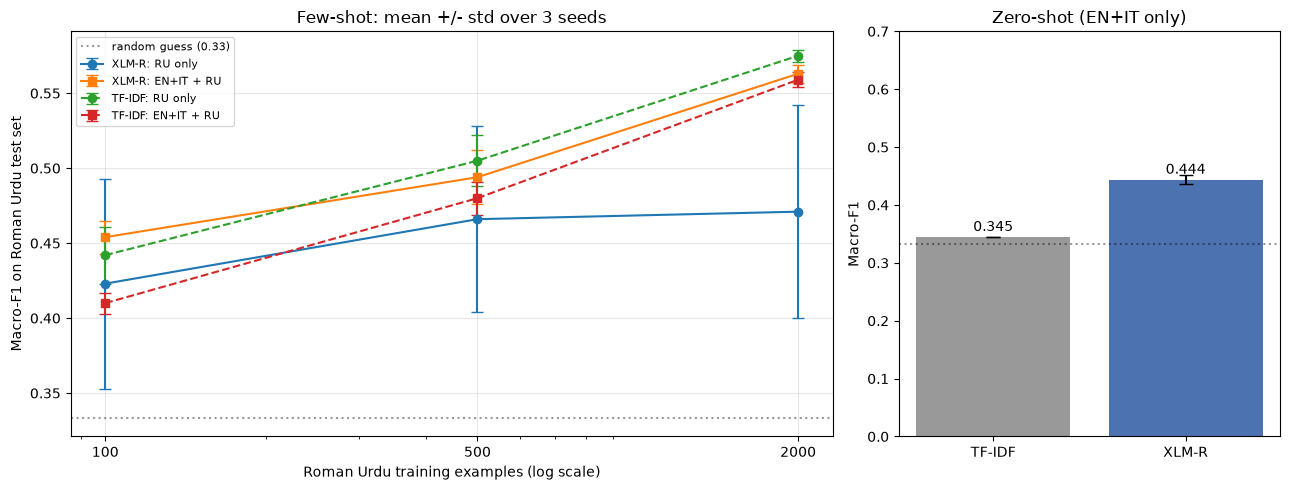

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [2, 1]})

def line(df, cond, label, fmt):
    d = df[(df['condition'] == cond) & (df['ru_n'].isin(SIZES))].sort_values('ru_n')
    ax1.errorbar(d['ru_n'], d['f1_mean'], yerr=d['f1_std'].fillna(0), fmt=fmt, capsize=4, label=label)

line(xlmr_sum, 'RU only', 'XLM-R: RU only', 'o-')
line(xlmr_sum, 'EN+IT + RU', 'XLM-R: EN+IT + RU', 's-')
line(tfidf_sum, 'RU only', 'TF-IDF: RU only', 'o--')
line(tfidf_sum, 'EN+IT + RU', 'TF-IDF: EN+IT + RU', 's--')
ax1.axhline(1/3, color='black', ls=':', alpha=0.4, label='random guess (0.33)')
ax1.set_xscale('log'); ax1.set_xticks(SIZES); ax1.set_xticklabels(SIZES)
ax1.set_xlabel('Roman Urdu training examples (log scale)'); ax1.set_ylabel('Macro-F1 on Roman Urdu test set')
ax1.set_title('Few-shot: mean +/- std over 3 seeds'); ax1.grid(alpha=0.3); ax1.legend(fontsize=8)

zs_t = tfidf_sum[tfidf_sum['condition'] == 'zero-shot EN+IT']['f1_mean'].iloc[0]
zs_x = xlmr_sum[xlmr_sum['condition'] == 'zero-shot EN+IT']['f1_mean'].iloc[0]
zs_x_std = xlmr_sum[xlmr_sum['condition'] == 'zero-shot EN+IT']['f1_std'].iloc[0]
ax2.bar(['TF-IDF', 'XLM-R'], [zs_t, zs_x], yerr=[0, zs_x_std], capsize=5, color=['#999999', '#4c72b0'])
ax2.axhline(1/3, color='black', ls=':', alpha=0.4)
for i, v in enumerate([zs_t, zs_x]):
    ax2.text(i, v + 0.01, f'{v:.3f}', ha='center')
ax2.set_ylim(0, 0.7); ax2.set_title('Zero-shot (EN+IT only)'); ax2.set_ylabel('Macro-F1')

plt.tight_layout()
plt.savefig(DOCS / 'combined_comparison.png', dpi=150)
plt.show()

## My notes (write in your own words)
1. **TF-IDF std over 3 seeds (RU only, EN+IT+RU, shuffled):** 
2. **At which Roman Urdu data size does TF-IDF match or beat XLM-R?** 
3. **Does the shuffled-label control also hurt TF-IDF? Compare with XLM-R.** 
4. **My conclusion: when is XLM-R worth using, and when is TF-IDF enough?** 

In [8]:
# ## My notes

# 1. **TF-IDF std over 3 seeds:** Small. RU only: 0.019 (100), 0.017 (500), 0.004 (2000).
#    EN+IT + RU: 0.007, 0.011, 0.005. Shuffled labels: 0.017, 0.006, 0.002.
#    TF-IDF is much more stable than XLM-R RU only (std 0.062 to 0.071).

# 2. **Where does TF-IDF match or beat XLM-R?** TF-IDF trained only on Roman Urdu beats
#    XLM-R trained only on Roman Urdu at every small size (+0.019, +0.039, +0.104) and
#    they tie with full data (0.653 vs 0.655). Compared with XLM-R + EN/IT data, TF-IDF
#    (RU only) is about equal at 100 (0.442 vs 0.454, ranges overlap), and equal or
#    slightly better at 500 (0.505 vs 0.494) and 2000 (0.575 vs 0.563).

# 3. **Shuffled-label control:** It hurts both models, but very differently.
#    XLM-R: 0.249, 0.203, 0.435 (vs 0.454, 0.494, 0.563 with real labels), with one
#    collapsed run. TF-IDF: 0.371, 0.460, 0.551 (vs 0.410, 0.480, 0.559). My
#    hypothesis: XLM-R really uses the English/Italian data (so correct labels help
#    and wrong labels hurt), while character-n-gram TF-IDF largely ignores it because
#    the words do not overlap. Adding English/Italian data also slightly lowers
#    TF-IDF (EN+IT+RU below RU only at all three sizes).

# 4. **Conclusion:** XLM-R is worth using when there are no Roman Urdu labels at all
#    (zero-shot 0.444 vs 0.345 for TF-IDF), and possibly when only about 100 labels
#    exist and English/Italian labeled data is available. As soon as a few hundred
#    Roman Urdu labels exist, a much cheaper TF-IDF + SVM model matches it (0.653 vs
#    0.655 with full data), trains on a CPU, and is more stable. Limits: one dataset,
#    3 seeds, no hyperparameter tuning for XLM-R (RU-only XLM-R may be under-trained),
#    and sentiment only (no topic/urgency).